# 01 · EDA y calidad de datos (tarea A2)

**Fase CRISP-DM:** comprensión de los datos. Dataset Rossmann Store Sales (Kaggle), 2013-01-01 a
2015-07-31. Debajo de cada gráfico hay una conclusión escrita.

Regla: `Customers` se mira solo de forma descriptiva; **nunca** es variable exógena (fuga de datos).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DATA_PROCESSED, LEVELS_TYPES
from src.data.load import load_raw

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

PROCESSED = DATA_PROCESSED / "rossmann.parquet"
if not PROCESSED.exists():
    from src.data.make_dataset import main as make_dataset
    make_dataset()

train_raw, store_raw = load_raw()
df = pd.read_parquet(PROCESSED)
obs = df[df["imputed"] == 0]          # solo registros originales
opened = obs[obs["Open"] == 1]
print(train_raw.shape, store_raw.shape, df.shape)

(1017209, 9) (1115, 10) (1050330, 22)


## 1. Revisión inicial

In [2]:
display(train_raw.dtypes.to_frame("dtype").T)
display(store_raw.dtypes.to_frame("dtype").T)
print("Rango de fechas:", train_raw["Date"].min().date(), "→", train_raw["Date"].max().date())
print("Tiendas:", train_raw["Store"].nunique(), "| días:", train_raw["Date"].nunique())
print("Valores de StateHoliday en el CSV:", train_raw["StateHoliday"].unique())
print("Nulos en store.csv:")
display(store_raw.isna().sum().to_frame("nulos").T)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
dtype,int64,int64,datetime64[ns],int64,int64,int64,int64,object,int64


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
dtype,int64,object,object,float64,float64,float64,int64,float64,float64,object


Rango de fechas: 2013-01-01 → 2015-07-31
Tiendas: 1115 | días: 942
Valores de StateHoliday en el CSV: ['0' 'a' 'b' 'c']
Nulos en store.csv:


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
nulos,0,0,0,3,354,354,0,544,544,544


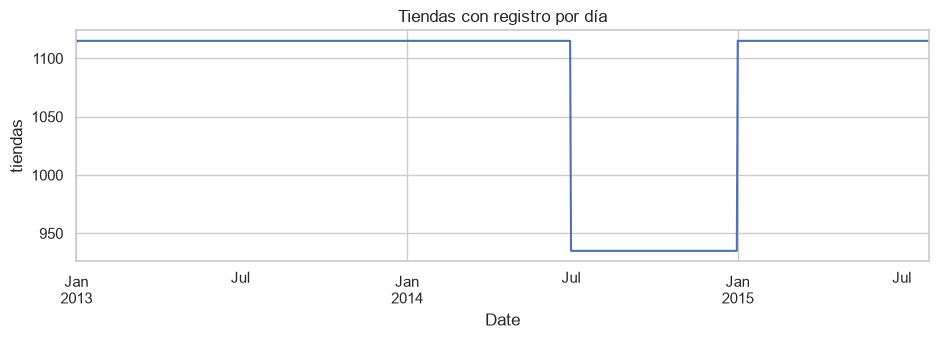

Días con tiendas faltantes: 185 | 2013-01-01 → 2014-12-31
Tiendas afectadas: 180


In [3]:
stores_per_day = train_raw.groupby("Date")["Store"].nunique()
ax = stores_per_day.plot(figsize=(11, 3), title="Tiendas con registro por día")
ax.set_ylabel("tiendas"); plt.show()
gap = stores_per_day[stores_per_day < stores_per_day.max()]
print("Días con tiendas faltantes:", len(gap), "|", gap.index.min().date(), "→", gap.index.max().date())
print("Tiendas afectadas:", stores_per_day.max() - gap.min())

> **Conclusión:** 1 017 209 filas × 9 columnas, 1 115 tiendas y 942 días (01/01/2013 a 31/07/2015). Leyendo `StateHoliday` como texto queda en {0, a, b, c} (D-06). En `store.csv` faltan `CompetitionDistance` en 3 tiendas (D-08) y la fecha de apertura del competidor en 354 (D-09); los 544 nulos de `Promo2Since*` y `PromoInterval` son estructurales (tiendas sin Promo2). **180 tiendas no tienen registros del 01/07/2014 al 31/12/2014** (y una tienda no tiene el 01/01/2013): es el hueco que se rellena en D-10.

## 2. Resumen estadístico de Sales (días abiertos)

In [4]:
for col in ["StoreType", "Assortment", "DayOfWeek", "Promo", "StateHoliday"]:
    print(f"— por {col}")
    display(opened.groupby(col)["Sales"].describe()[["count", "mean", "50%", "std", "min", "max"]])

— por StoreType


,count,mean,50%,std,min,max
StoreType,,,,,,
a,"457,077.00","6,925.17","6,285.00","3,277.79",0.00,"41,551.00"
b,"15,563.00","10,231.41","9,130.00","5,157.19",0.00,"38,722.00"
c,"112,978.00","6,932.51","6,407.00","2,897.56",0.00,"31,448.00"
d,"258,774.00","6,822.14","6,395.00","2,556.58",0.00,"38,037.00"


— por Assortment


,count,mean,50%,std,min,max
Assortment,,,,,,
a,"444,909.00","6,621.02","6,082.00","2,972.50",0.00,"38,722.00"
b,"8,212.00","8,639.35","8,081.00","3,806.01",0.00,"22,137.00"
c,"391,271.00","7,300.53","6,675.00","3,184.14",0.00,"41,551.00"


— por DayOfWeek


,count,mean,50%,std,min,max
DayOfWeek,,,,,,
1,"137,560.00","8,216.07","7,539.00","3,691.77",0.00,"41,551.00"
2,"143,961.00","7,088.11","6,502.00","3,066.24",0.00,"34,692.00"
3,"141,936.00","6,728.12","6,210.00","2,781.78",0.00,"33,151.00"
4,"134,644.00","6,767.31","6,246.00","2,764.55",0.00,"38,367.00"
5,"138,640.00","7,072.68","6,580.00","2,764.92",0.00,"38,722.00"
6,"144,058.00","5,874.84","5,425.00","2,852.73",0.00,"31,683.00"
7,"3,593.00","8,224.72","6,876.00","6,235.15",286.00,"37,376.00"


— por Promo


,count,mean,50%,std,min,max
Promo,,,,,,
0,"467,496.00","5,929.41","5,459.00","2,629.65",0.00,"41,551.00"
1,"376,896.00","8,228.28","7,649.00","3,175.76",0.00,"38,722.00"


— por StateHoliday


,count,mean,50%,std,min,max
StateHoliday,,,,,,
0,"843,482.00","6,953.52","6,368.00","3,098.87",0.00,"41,551.00"
a,694.00,"8,487.47","7,556.00","5,708.63","1,010.00","38,484.00"
b,145.00,"9,887.89","8,423.00","7,551.78",960.00,"38,722.00"
c,71.00,"9,743.75","8,397.00","5,980.86","1,800.00","32,169.00"


> **Conclusión:** En días abiertos, el tipo **b** vende ~10 200 € por tienda y día frente a ~6 900 € de a, c y d, y es el único que abre en domingo. El surtido **b** (extra) vende más que el básico. El **lunes** es el día más alto (8 216 €) y el sábado el más bajo de los hábiles (5 875 €). Con **promo** la venta media sube de 5 929 € a 8 228 € (+39 %). En festivos abren muy pocas tiendas, pero las que abren venden más que un día normal.

## 3. Outliers

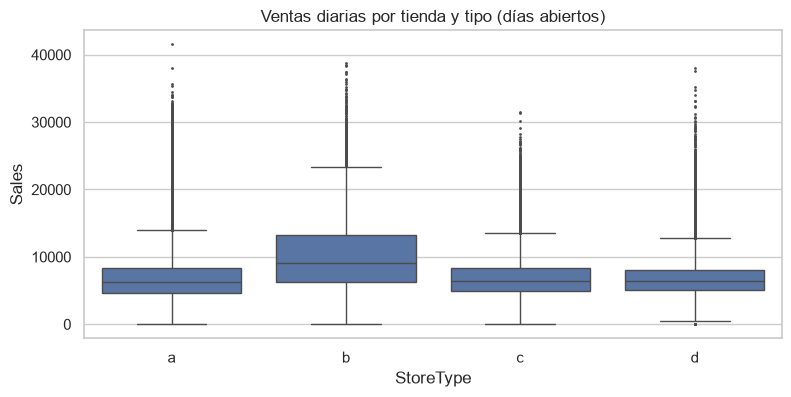

Top 10 días más altos (total):


,Sales
Date,
2013-12-16,15623548
2013-12-23,14350056
2014-12-15,13811176
2014-06-30,13308602
2013-12-17,13053993
2013-12-02,12972440
2015-03-30,12371453
2013-12-20,12334496
2013-12-18,12189674


Top 10 días más bajos con tiendas abiertas:


,Sales
Date,
2013-12-31,4534864
2014-11-01,4652280
2014-12-31,4938103
2013-12-24,5232808
2013-01-16,5293020
2013-03-12,5338418
2013-01-17,5386564
2013-08-24,5397910
2013-09-18,5438193


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=opened, x="StoreType", y="Sales", order=list("abcd"), ax=ax, fliersize=1)
ax.set_title("Ventas diarias por tienda y tipo (días abiertos)"); plt.show()

total = df.groupby("Date")["Sales"].sum()
print("Top 10 días más altos (total):"); display(total.nlargest(10).to_frame("Sales"))
print("Top 10 días más bajos con tiendas abiertas:")
open_days = df.groupby("Date")["Open"].mean() > 0.5
display(total[open_days].nsmallest(10).to_frame("Sales"))

> **Conclusión:** Todas las distribuciones tienen cola larga a la derecha. Los días más altos del total son las semanas antes de Navidad (diciembre de 2013 y 2014) y lunes con promo de fin de trimestre (31/03/2014, 30/06/2014, 30/03/2015); los más bajos con tiendas abiertas son 24/12 y 31/12 (cierre temprano) y 01/11/2014 (Todos los Santos, festivo regional). Son **picos reales del negocio, no errores**: no se eliminan; la estacionalidad anual y las exógenas de festivos deben explicarlos.

## 4. Visualización

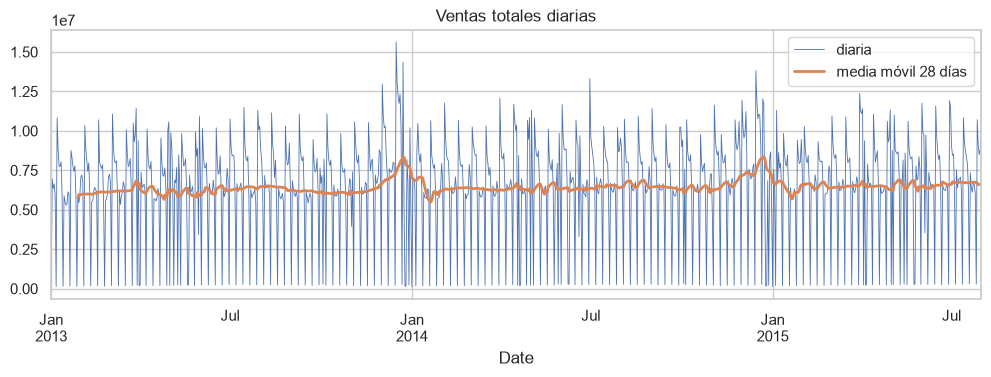

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.5))
total.plot(ax=ax, lw=0.6, label="diaria")
total.rolling(28).mean().plot(ax=ax, lw=2, label="media móvil 28 días")
ax.set_title("Ventas totales diarias"); ax.legend(); plt.show()

> **Conclusión:** Patrón semanal muy marcado (los domingos el total cae casi a cero), pico anual en diciembre y nivel estable, sin tendencia fuerte entre 2013 y 2015. Justifica s = 7 para la parte semanal y un término anual (Fourier) aparte.

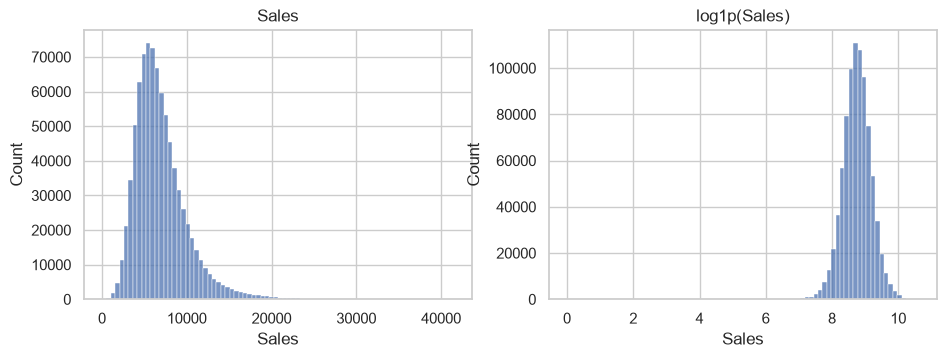

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(opened["Sales"], bins=80, ax=axes[0]); axes[0].set_title("Sales")
sns.histplot(np.log1p(opened["Sales"]), bins=80, ax=axes[1]); axes[1].set_title("log1p(Sales)")
plt.show()

> **Conclusión:** `Sales` es asimétrica a la derecha; `log1p(Sales)` es mucho más simétrica. Se modela en escala log1p (`log_target = true`) y se revierte con `expm1` al reportar.

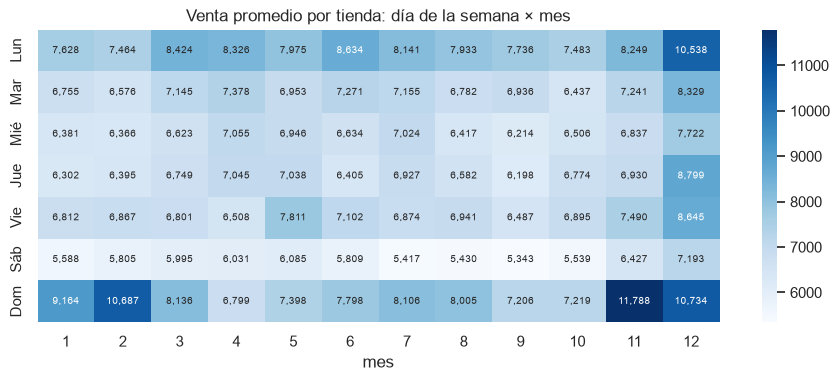

In [8]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
heat = (opened.assign(dow=opened["Date"].dt.dayofweek, mes=opened["Date"].dt.month)
        .pivot_table(index="dow", columns="mes", values="Sales", aggfunc="mean"))
heat.index = [dias[i] for i in heat.index]
plt.figure(figsize=(11, 3.8))
sns.heatmap(heat, cmap="Blues", fmt=",.0f", annot=True, annot_kws={"size": 7})
plt.title("Venta promedio por tienda: día de la semana × mes"); plt.show()

> **Conclusión:** El lunes es el día más alto en todos los meses y diciembre el mes más alto. La venta por tienda en domingo (solo tipo b) es alta pero con muy pocas tiendas abiertas.

,Sin promo,Con promo,uplift_%
StoreType,,,
a,"5,808.50","8,304.10",42.96
b,"9,566.86","11,307.99",18.20
c,"6,028.06","8,042.00",33.41
d,"5,855.27","8,017.83",36.93


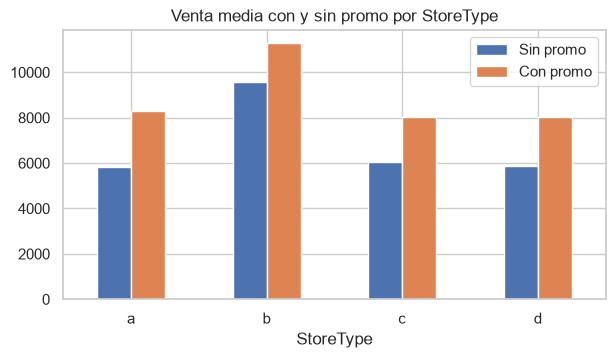

In [9]:
promo = opened.groupby(["StoreType", "Promo"])["Sales"].mean().unstack()
promo.columns = ["Sin promo", "Con promo"]
promo["uplift_%"] = (promo["Con promo"] / promo["Sin promo"] - 1) * 100
display(promo)
promo[["Sin promo", "Con promo"]].plot.bar(figsize=(7, 3.5), rot=0,
                                            title="Venta media con y sin promo por StoreType")
plt.show()

> **Conclusión:** Respuesta descriptiva a la promo por tipo: **a +43 %**, d +37 %, c +33 % y **b +18 %**. El tipo a parece el que mejor responde y el b el que menos. Es una comparación sin controles (los días con promo también difieren en día de la semana); el efecto aislado lo estima el SARIMAX (A7).

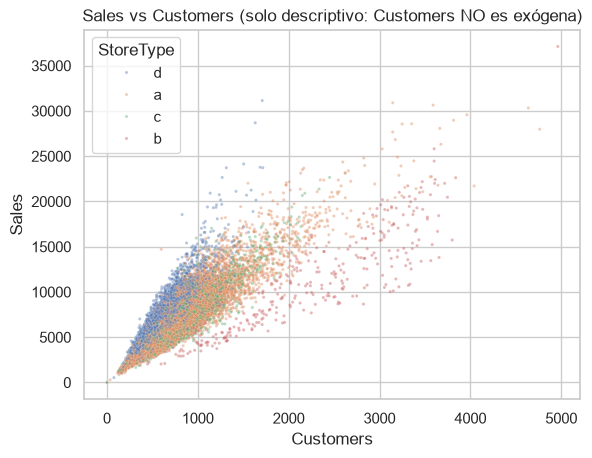

Correlación: 0.824


In [10]:
sample = opened.sample(min(20_000, len(opened)), random_state=42)
sns.scatterplot(data=sample, x="Customers", y="Sales", hue="StoreType", s=5, alpha=0.4)
plt.title("Sales vs Customers (solo descriptivo: Customers NO es exógena)"); plt.show()
print("Correlación:", round(opened[["Sales", "Customers"]].corr().iat[0, 1], 3))

> **Conclusión:** Correlación Sales–Customers = 0,82: casi la misma información que la venta. Por eso mismo **no se usa como exógena**: el número de clientes futuro no se conoce al pronosticar (fuga de datos).

## 5. Anomalías y efecto del relleno del hueco (D-07, D-10)

Días abiertos con ventas 0: 54 (0.005 % de las filas)
Filas imputadas: 33121 | tiendas: 181


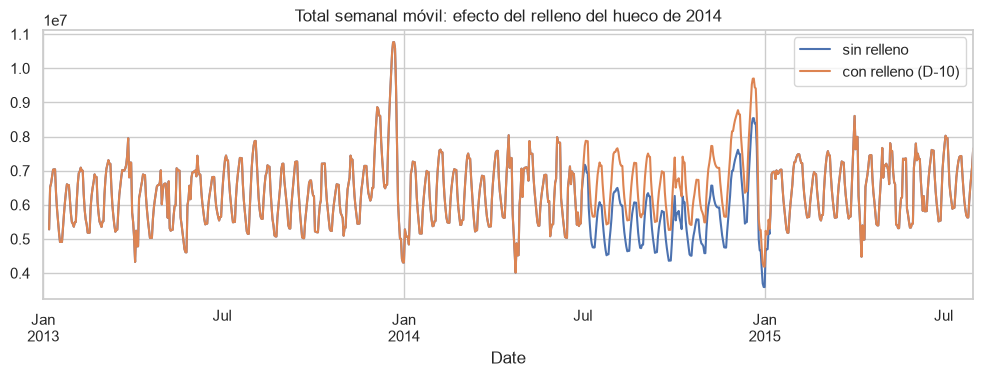

In [11]:
print("Días abiertos con ventas 0:", int(obs["anomaly_open_zero"].sum()),
      f"({obs['anomaly_open_zero'].mean() * 100:.3f} % de las filas)")
print("Filas imputadas:", int(df["imputed"].sum()), "| tiendas:", df.loc[df.imputed == 1, "Store"].nunique())
fig, ax = plt.subplots(figsize=(12, 3.5))
obs.groupby("Date")["Sales"].sum().rolling(7).mean().plot(ax=ax, label="sin relleno")
total.rolling(7).mean().plot(ax=ax, label="con relleno (D-10)")
ax.set_title("Total semanal móvil: efecto del relleno del hueco de 2014"); ax.legend(); plt.show()

> **Conclusión:** Solo 54 días abiertos con venta 0 (0,005 % de las filas): se dejan marcados y no afectan a las series agregadas. El relleno de D-10 agrega 33 121 tienda-días; **sin él, la venta total del segundo semestre de 2014 quedaría 15 % por debajo** (1 042 M€ frente a 1 231 M€), un falso cambio de nivel que confundiría a los modelos.

## 6. Checklist de calidad ISO/IEC 25012

In [12]:
iso = pd.DataFrame([
    ["Exactitud", "Días abiertos con Sales = 0", int(obs["anomaly_open_zero"].sum())],
    ["Exactitud", "Ventas negativas", int((obs["Sales"] < 0).sum())],
    ["Completitud", "Pares (tienda, fecha) faltantes", int(df["imputed"].sum())],
    ["Completitud", "Nulos en CompetitionDistance", int(store_raw["CompetitionDistance"].isna().sum())],
    ["Completitud", "Nulos en CompetitionOpenSince*", int(store_raw["CompetitionOpenSinceYear"].isna().sum())],
    ["Consistencia", "Tipos distintos en StateHoliday (crudo)", int(train_raw["StateHoliday"].map(type).nunique())],
    ["Consistencia", "Cerrado con ventas > 0", int(((obs["Open"] == 0) & (obs["Sales"] > 0)).sum())],
    ["Consistencia", "Duplicados (Store, Date)", int(train_raw.duplicated(["Store", "Date"]).sum())],
    ["Credibilidad", "Días con venta total > p99.9", int((total > total.quantile(0.999)).sum())],
    ["Actualidad", "Última fecha", str(train_raw["Date"].max().date())],
], columns=["Dimensión", "Chequeo", "Resultado"])
iso

,Dimensión,Chequeo,Resultado
0,Exactitud,Días abiertos con Sales = 0,54
1,Exactitud,Ventas negativas,0
2,Completitud,"Pares (tienda, fecha) faltantes",33121
3,Completitud,Nulos en CompetitionDistance,3
4,Completitud,Nulos en CompetitionOpenSince*,354
5,Consistencia,Tipos distintos en StateHoliday (crudo),1
6,Consistencia,Cerrado con ventas > 0,0
7,Consistencia,"Duplicados (Store, Date)",0
8,Credibilidad,Días con venta total > p99.9,1
9,Actualidad,Última fecha,2015-07-31


> **Conclusión:** **Exactitud:** buena (sin ventas negativas; 54 anomalías marcadas). **Completitud:** el problema principal es el hueco de 2014 (33 121 pares), resuelto con D-10 sin usar el futuro; los nulos de `store.csv` se tratan en D-08 y D-09. **Consistencia:** sin duplicados, ninguna tienda cerrada con ventas y `StateHoliday` unificado. **Credibilidad:** los extremos son días de Navidad y fin de trimestre, creíbles. **Actualidad:** los datos terminan el 31/07/2015, una limitación que se declara en la app.

## 7. Selección de las 5 tiendas (`SELECTED_STORES`)

Criterio: una por StoreType con historia completa (sin imputación ni días abiertos con venta 0) y venta cercana a la mediana de su tipo, más una con alta respuesta a la promo.

In [13]:
complete = obs.groupby("Store").agg(n=("Date", "nunique"), anom=("anomaly_open_zero", "sum"))
complete = complete[(complete["n"] == obs["Date"].nunique()) & (complete["anom"] == 0)].index

wk = opened[opened["Date"].dt.dayofweek < 5]
uplift = (wk.groupby(["Store", "Promo"])["Sales"].mean().unstack()
            .pipe(lambda t: t[1] / t[0] - 1).rename("uplift"))
info = (opened.groupby("Store").agg(sales=("Sales", "mean"), StoreType=("StoreType", "first"))
          .join(uplift).loc[lambda t: t.index.isin(complete)])

chosen = []
for t in "abcd":
    g = info[info["StoreType"] == t]
    if g.empty:
        print(f"Tipo {t}: ninguna tienda con historia completa")
        continue
    chosen.append(int((g["sales"] - g["sales"].median()).abs().idxmin()))
# alta respuesta a la promo entre tiendas de venta típica o mayor (en tiendas muy chicas el
# MAPE es inestable)
big = info["sales"] >= opened.groupby("Store")["Sales"].mean().median()
rest = info[big].drop(index=chosen, errors="ignore")["uplift"].dropna()
if len(rest):
    chosen.append(int(rest.idxmax()))
display(info.loc[chosen])
print("Propuesta SELECTED_STORES =", chosen)

,sales,StoreType,uplift
Store,,,
9,"6,562.34",a,0.36
769,"10,825.90",b,0.11
504,"6,673.16",c,0.25
960,"6,723.60",d,0.52
693,"6,607.94",d,1.01


Propuesta SELECTED_STORES = [9, 769, 504, 960, 693]


> **Conclusión:** `SELECTED_STORES = [9, 769, 504, 960, 693]`. Las cuatro primeras son una por
> tipo (a, b, c, d), con historia completa y venta cercana a la mediana de su tipo. La **693**
> (tipo d) es la de mayor respuesta a la promo (~+100 % de lunes a viernes) entre las tiendas con
> venta igual o mayor a la mediana. Se descartó la 198, que responde igual pero vende ~2 900 €/día:
> en una tienda tan chica el MAPE es muy inestable. Fijado en `src/config.py` (D-11); el
> `history.parquet` se regenera con `python -m src.features.exog`.

## 8. Validación de D-01 (domingos y `open_share`)

In [14]:
sun = df[df["Date"].dt.dayofweek == 6]
print(f"Tiendas abiertas en domingo: {sun['Open'].mean() * 100:.2f} % de tienda-días")
print("Por tipo:"); display(sun.groupby("StoreType")["Open"].mean().to_frame("open_share domingo"))
share = df.groupby(df["Date"].dt.dayofweek)["Sales"].sum() / df["Sales"].sum() * 100
display(share.rename(index=dict(enumerate(dias))).to_frame("% de la venta"))

Tiendas abiertas en domingo: 2.42 % de tienda-días
Por tipo:


,open_share domingo
StoreType,
a,0.01
b,0.98
c,0.00
d,0.01


,% de la venta
Date,
Lun,19.23
Mar,17.36
Mié,16.28
Jue,15.50
Vie,16.70
Sáb,14.44
Dom,0.49


> **Conclusión D-01: se valida.** Solo el 2,4 % de los tienda-días de domingo están abiertos y el
> domingo aporta el 0,5 % de la venta. Los tipos a, c y d casi nunca abren en domingo; el tipo b
> abre el 98 % de los domingos. Una serie diaria con domingos, s = 7 y la exógena `open_share`
> (conocida de antemano) representa bien ambos casos sin quitar días, y mantiene el calendario
> continuo que necesitan SARIMAX y la GRU. El MAPE se calcula solo con y > 0, así que los domingos
> cerrados no lo distorsionan.